# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [10]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [11]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [12]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:46759/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [21]:
# Write your solution here.
import re
from pathlib import Path
from bs4 import BeautifulSoup
import pandas as pd

orders_data = []
total_pages = 16

for i in range(1, total_pages + 1):
  html_path = Path(f"data/site/catalogue/page-{i}.html")
  if not html_path.exists():
    continue

  html = html_path.read_text(encoding="utf-8")
  soup = BeautifulSoup(html, "html.parser")

  for article in soup.select("article.card.order"):
    order_id = article.get("data-id") or article.get("id").replace("order-", "")

    title_el = article.select_one("h2.title")
    restaurant = title_el.get_text(strip=True) if title_el else None

    cuisine, city = None, None
    place_el = article.select_one("p.place")
    if place_el:
      c_el = place_el.select_one("span.cuisine")
      ci_el = place_el.select_one("span.city")
      cuisine = c_el.get_text(strip=True) if c_el else None
      city = ci_el.get_text(strip=True) if ci_el else None

    delivery_el = article.select_one("p.delivery")
    minutes = None
    if delivery_el:
      
      m_match = re.search(r"Delivered in (\d+) minutes", delivery_el.get_text())
      if m_match:

        minutes = int(m_match.group(1))

    summary_el = article.select_one("p.summary")
    distance, unit = None, None
    if summary_el:
      
      s_match = re.search(r"A trip of ([\d\s\.]+) ([a-zA-Z]+) from", summary_el.get_text())
      if s_match:

        distance = s_match.group(1).strip()
        unit = s_match.group(2).strip()

    slot, weather, payment, rating = None, None, None, None
    for li in article.select("ul.tags > li"):
      classes = li.get("class", [])
      text = li.get_text(strip=True)
      if "slot" in classes:
        slot = text
      elif "weather" in classes:
        weather = text
      elif "payment" in classes:
        payment = text
      elif "rating" in classes:
        r_match = re.search(r"Rated (\d+) of 5", text)
        rating = int(r_match.group(1)) if r_match else text

    courier_el = article.select_one("p.courier")
    by_restaurant = None
    if courier_el:
      c_text = courier_el.get_text(strip=True)
      if "Delivered by the restaurant" in c_text:
        by_restaurant = True
      elif "Delivered by a City Delivery courier" in c_text:
        by_restaurant = False

    orders_data.append({
        "order_id": order_id,
        "restaurant": restaurant,
        "cuisine": cuisine,
        "city": city,
        "distance": distance,
        "unit": unit,
        "minutes": minutes,
        "slot": slot,
        "weather": weather,
        "payment": payment,
        "rating": rating,
        "by_restaurant": by_restaurant,
    })

orders = pd.DataFrame(orders_data)

print(f"Total orders collected: {len(orders)}")
print(f"Spread across {total_pages} pages.")

Total orders collected: 192
Spread across 16 pages.


## Task 2: Add the Receipts

The home page of the service, `index.html` under `BASE`, points to a page of receipts. Collect every receipt the page holds, and add the items, the total, and the tip of each order to `orders`, so that every order appears exactly once. Name the result `df`.

Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [ ]:
# Write your solution here.
receipts_html_path = Path("data/site/receipts.html")
receipts_html = receipts_html_path.read_text(encoding="utf-8")
soup_receipts = BeautifulSoup(receipts_html, "html.parser")

script_tag = soup_receipts.find("script")
match = re.search(r"const RECEIPTS = (\[.*?\]);", script_tag.string, re.DOTALL)

receipts_data = []
if match:
  receipts_data = json.loads(match.group(1))

receipts_df = pd.DataFrame(receipts_data)

total_receipts_in_data = len(receipts_df)

duplicates_count = receipts_df.duplicated(subset=["order_id"]).sum()

receipts_df = receipts_df.drop_duplicates(subset=["order_id"], keep="first")
collected_unique_receipts = len(receipts_df)

orders["order_id"] = orders["order_id"].astype(int)
receipts_df["order_id"] = receipts_df["order_id"].astype(int)

df = orders.merge(receipts_df, on="order_id", how="left")

print(f"Receipts the page holds (in script data): {total_receipts_in_data}")
print(f"Receipts collected (unique): {collected_unique_receipts}")
print(
    "Duplicate handling: Found duplicate entries (e.g., order_id 510546 appears"
    " twice). Dropped the duplicates keeping the first occurrence so every"
    " order appears in `df` exactly once."
)
print(f"Final df shape: {df.shape}")

Receipts the page holds (in script data): 193
Receipts collected (unique): 192
Duplicate handling: Found duplicate entries (e.g., order_id 510546 appears twice). Dropped the duplicates keeping the first occurrence so every order appears in `df` exactly once.
Final df shape: (192, 15)


## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [ ]:
# Write your solution here.

df["distance"] = (
    df["distance"].astype(str).str.replace(" ", "", regex=False).astype(float)
)

slot_cat_type = pd.CategoricalDtype(
    categories=["Lunch", "Dinner", "Late night"], ordered=True
)

df = df.astype({
    "order_id": "string",
    "restaurant": "category",
    "cuisine": "category",
    "city": "category",
    "distance": "float64",
    "unit": "category",
    "minutes": "Int64",  
    "weather": "category",
    "payment": "category",
    "rating": "Int64",  
    "by_restaurant": "bool",
    "items": "Int64",
    "total": "int64",
    "tip": "int64",
})

df["slot"] = df["slot"].astype(slot_cat_type)

print(df.dtypes)

order_id           string
restaurant       category
cuisine          category
city             category
distance          float64
unit             category
minutes             Int64
slot             category
weather          category
payment          category
rating              Int64
by_restaurant        bool
items               Int64
total               int64
tip                 int64
dtype: object


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

         Missing Count  Missing Percentage (%)
minutes             42                   21.88
rating              24                   12.50


/tmp/ipykernel_127740/2673982698.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


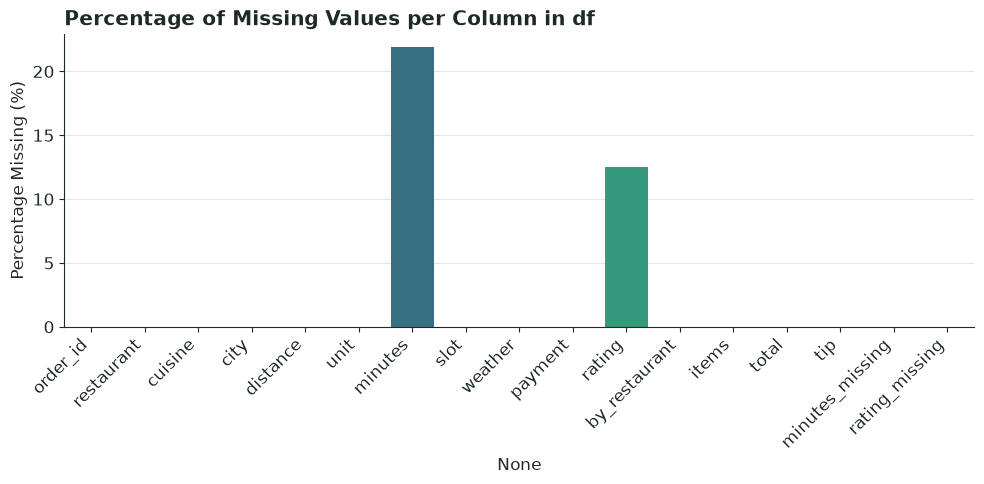

--- Missing Minutes vs By Restaurant ---
minutes_missing     False     True 
by_restaurant                      
False            0.929577  0.070423
True             0.360000  0.640000

--- Missing Ratings vs By Restaurant ---
rating_missing     False     True 
by_restaurant                     
False           0.873239  0.126761
True            0.880000  0.120000


In [ ]:
# Write your solution here.

missing_counts = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_df = pd.DataFrame(
    {"Missing Count": missing_counts, "Missing Percentage (%)": missing_pct}
)

print(missing_df[missing_df["Missing Count"] > 0])

plt.figure(figsize=(10, 5))
sns.barplot(
    x=df.columns,
    y=df.isnull().mean() * 100,
    palette="viridis",
    hue=df.columns,
    legend=False,
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage Missing (%)")
plt.title("Percentage of Missing Values per Column in df")
plt.tight_layout()
plt.show()

df["minutes_missing"] = df["minutes"].isnull()
df["rating_missing"] = df["rating"].isnull()

print("--- Missing Minutes vs By Restaurant ---")
print(pd.crosstab(df["by_restaurant"], df["minutes_missing"], normalize="index"))

print("\n--- Missing Ratings vs By Restaurant ---")
print(pd.crosstab(df["by_restaurant"], df["rating_missing"], normalize="index"))

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

In [ ]:
# Write your solution here.
df["distance_num"] = (
    df["distance"].astype(str).str.replace(" ", "", regex=False).astype(float)
)

distance_comparison = df.groupby("unit")["distance_num"].describe()
print(distance_comparison)

df["distance_km"] = np.where(
    df["unit"] == "m",
    df["distance_num"] / 1000.0,  
    df["distance_num"],  
)

df = df.drop(columns=["distance_num"])

print(df[["distance", "unit", "distance_km"]].head(10))

      count         mean          std     min     25%     50%     75%     max
unit                                                                         
km    162.0     3.230247     1.276013     1.3     2.3     2.9     4.1     8.0
m      30.0  2498.333333  1066.777562  1200.0  1650.0  2375.0  2887.5  5350.0
   distance unit  distance_km
0       5.0   km         5.00
1    3650.0    m         3.65
2    4700.0    m         4.70
3       2.7   km         2.70
4       2.4   km         2.40
5       3.6   km         3.60
6       3.2   km         3.20
7       1.7   km         1.70
8       3.9   km         3.90
9    4450.0    m         4.45


### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

--- Center ---
Mean delivery time: 29.78 minutes
Median delivery time: 27.00 minutes

--- Spread ---
Standard Deviation: 10.28
IQR: 11.00 (Q1: 23.0, Q3: 34.0)
Min: 12 min, Max: 72 min

--- Shape ---
Skewness: 1.43


/tmp/ipykernel_127740/1024609851.py:50: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


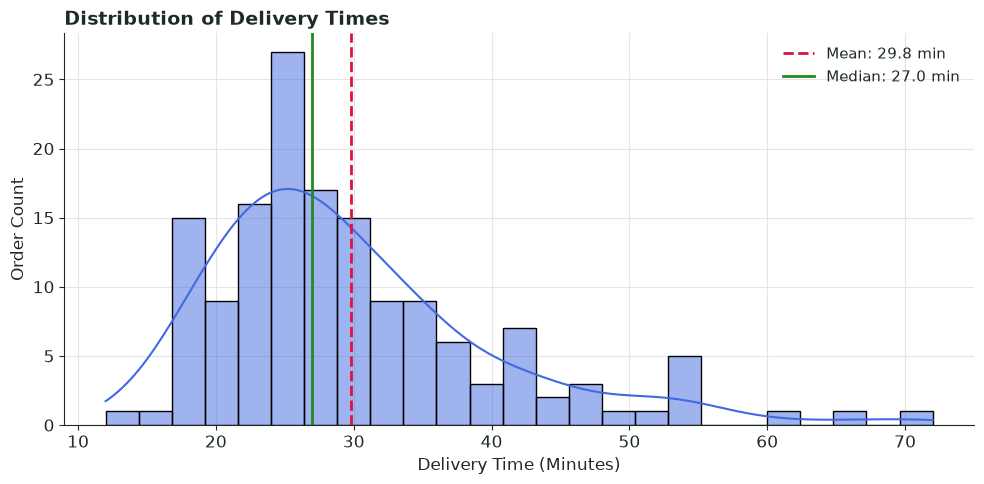

In [ ]:
# Write your solution here.
minutes_clean = df["minutes"].dropna()

mean_time = minutes_clean.mean()
median_time = minutes_clean.median()
std_time = minutes_clean.std()
q25 = minutes_clean.quantile(0.25)
q75 = minutes_clean.quantile(0.75)
iqr_time = q75 - q25
min_time = minutes_clean.min()
max_time = minutes_clean.max()
skewness = minutes_clean.skew()

print(f"--- Center ---")
print(f"Mean delivery time: {mean_time:.2f} minutes")
print(f"Median delivery time: {median_time:.2f} minutes")

print(f"\n--- Spread ---")
print(f"Standard Deviation: {std_time:.2f}")
print(f"IQR: {iqr_time:.2f} (Q1: {q25}, Q3: {q75})")
print(f"Min: {min_time} min, Max: {max_time} min")

print(f"\n--- Shape ---")
print(f"Skewness: {skewness:.2f}")

plt.figure(figsize=(10, 5))
sns.histplot(minutes_clean, kde=True, bins=25, color="royalblue")
plt.axvline(
    mean_time,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_time:.1f} min",
)
plt.axvline(
    median_time,
    color="forestgreen",
    linestyle="-",
    linewidth=2,
    label=f"Median: {median_time:.1f} min",
)
plt.title("Distribution of Delivery Times", fontsize=14)
plt.xlabel("Delivery Time (Minutes)", fontsize=12)
plt.ylabel("Order Count", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

         slot  Count   Mean  Median    Std    Q25  Q75   IQR
0       Lunch     45  28.93    27.0   9.61   23.0   31   8.0
1      Dinner     61  30.75    28.0    9.5   24.0   35  11.0
2  Late night     44   29.3    26.0  11.99  22.75   32  9.25


/tmp/ipykernel_127740/3264471999.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_127740/3264471999.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


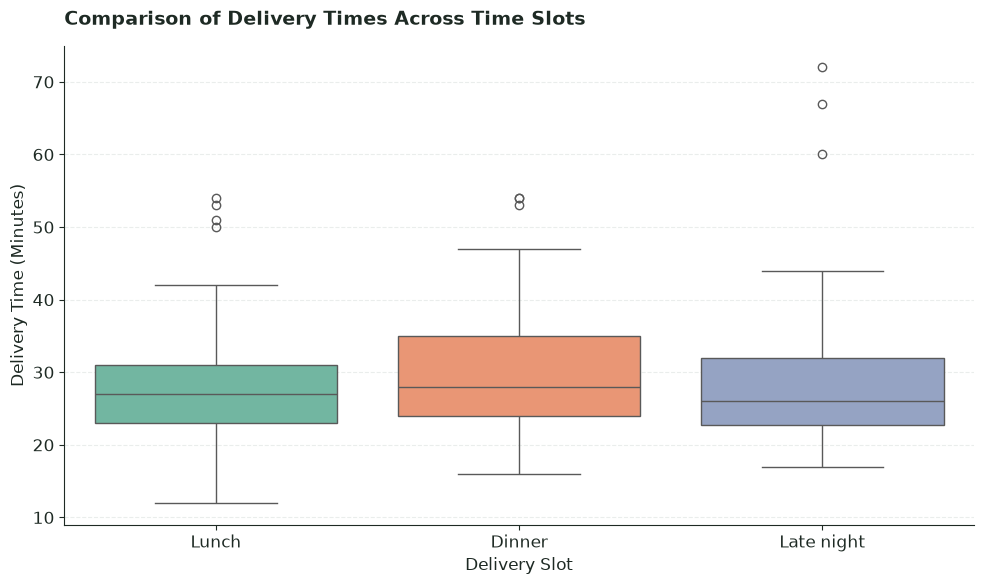

In [ ]:
# Write your solution here.
slot_stats = (
    df.groupby("slot", observed=False)["minutes"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)
slot_stats["IQR"] = slot_stats["Q75"] - slot_stats["Q25"]
print(slot_stats.round(2))

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="slot",
    y="minutes",
    palette="Set2",
    order=["Lunch", "Dinner", "Late night"],
)
plt.title(
    "Comparison of Delivery Times Across Time Slots", fontsize=14, pad=15
)
plt.xlabel("Delivery Slot", fontsize=12)
plt.ylabel("Delivery Time (Minutes)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

       city  count  share_pct
0    Skopje     99      51.56
1    Tetovo     24      12.50
2  Kumanovo     22      11.46
3    Bitola     18       9.38
4     Ohrid     15       7.81
5    Prilep     14       7.29


/tmp/ipykernel_127740/264698166.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


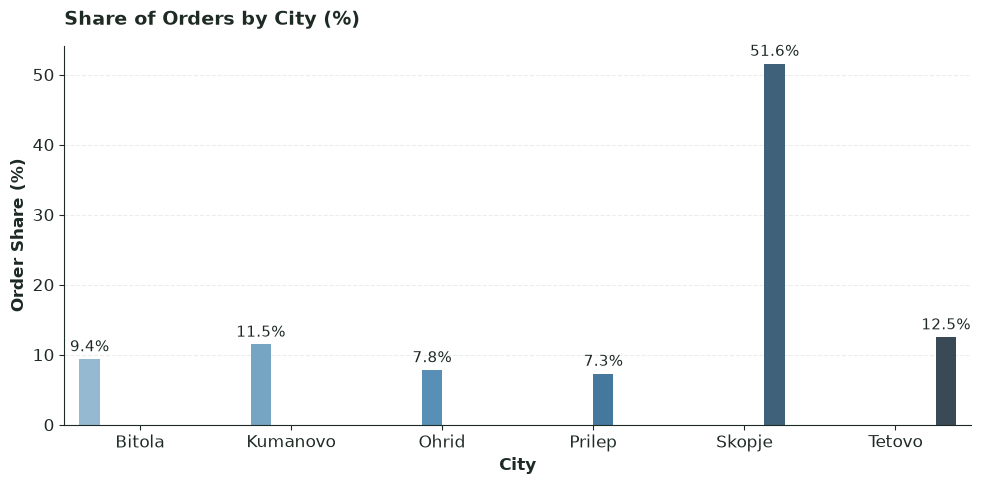

In [ ]:
# Write your solution here.
city_counts = df["city"].value_counts().reset_index()
city_counts.columns = ["city", "count"]
city_counts["share_pct"] = (
    city_counts["count"] / city_counts["count"].sum() * 100
)

print(city_counts.round(2))

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=city_counts,
    x="city",
    y="share_pct",
    palette="Blues_d",
    hue="city",
    legend=False,
)
plt.title("Share of Orders by City (%)", fontsize=14, pad=15)
plt.xlabel("City", fontsize=12, fontweight="bold")
plt.ylabel("Order Share (%)", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.7)

for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f"{height:.1f}%",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=11,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson Correlation Coefficient: 0.881
Spearman Correlation Coefficient: 0.869


/tmp/ipykernel_127740/3169212827.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


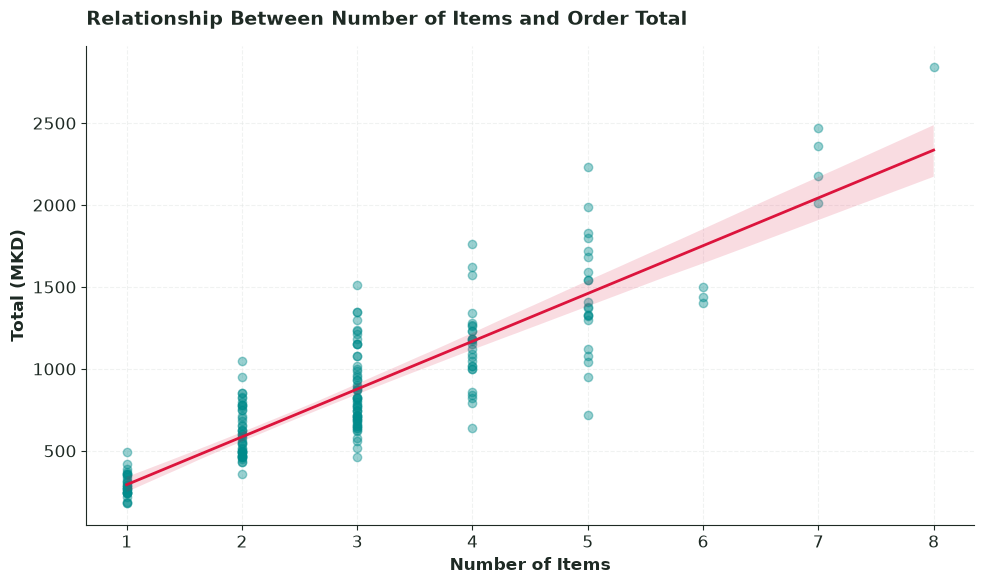

In [ ]:
# Write your solution here.
valid_df = df.dropna(subset=["items", "total"])

pearson_corr = valid_df["items"].corr(valid_df["total"], method="pearson")
spearman_corr = valid_df["items"].corr(valid_df["total"], method="spearman")

print(f"Pearson Correlation Coefficient: {pearson_corr:.3f}")
print(f"Spearman Correlation Coefficient: {spearman_corr:.3f}")

plt.figure(figsize=(10, 6))
sns.regplot(
    data=valid_df,
    x="items",
    y="total",
    scatter_kws={"alpha": 0.4, "color": "darkcyan"},
    line_kws={"color": "crimson", "linewidth": 2},
)
plt.title(
    "Relationship Between Number of Items and Order Total",
    fontsize=14,
    pad=15,
)
plt.xlabel("Number of Items", fontsize=12, fontweight="bold")
plt.ylabel("Total (MKD)", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

Spearman Correlation Matrix:
             distance_km  minutes  rating  items  total    tip
distance_km        1.000    0.590  -0.309 -0.005  0.003  0.021
minutes            0.590    1.000  -0.415 -0.066 -0.036  0.071
rating            -0.309   -0.415   1.000  0.082  0.088 -0.041
items             -0.005   -0.066   0.082  1.000  0.869  0.423
total              0.003   -0.036   0.088  0.869  1.000  0.463
tip                0.021    0.071  -0.041  0.423  0.463  1.000

Strongest Pair: **items** and **total** (Spearman Correlation = 0.869)


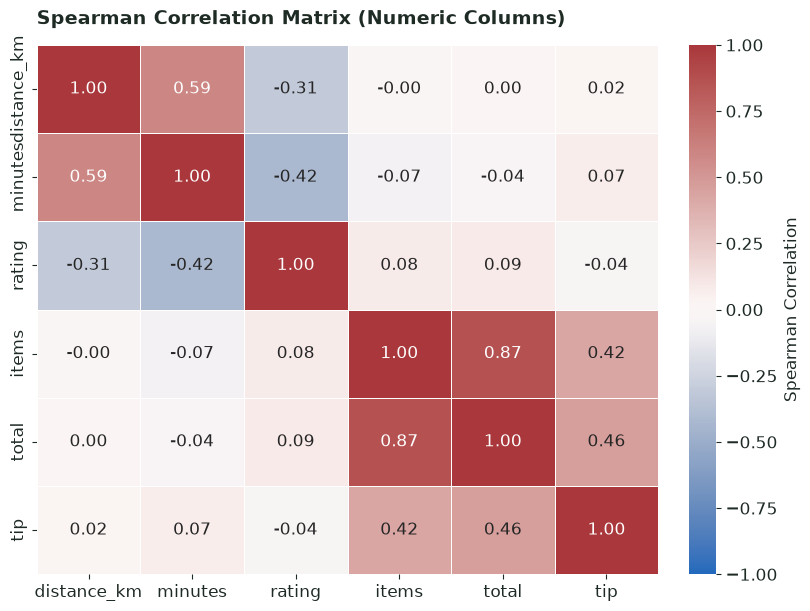

In [ ]:
numeric_cols = ["distance_km", "minutes", "rating", "items", "total", "tip"]

for col in numeric_cols:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

spearman_matrix = df[numeric_cols].corr(method="spearman")
print("Spearman Correlation Matrix:")
print(spearman_matrix.round(3))

corr_unstacked = spearman_matrix.abs().unstack().reset_index(name="corr_val")
corr_unstacked = corr_unstacked[
    corr_unstacked["level_0"] != corr_unstacked["level_1"]
]
corr_unstacked["pair"] = corr_unstacked.apply(
    lambda row: tuple(sorted([row["level_0"], row["level_1"]])), axis=1
)
corr_unstacked = corr_unstacked.drop_duplicates(subset=["pair"])
strongest = corr_unstacked.sort_values(by="corr_val", ascending=False).iloc[0]

actual_corr = spearman_matrix.loc[strongest["level_0"], strongest["level_1"]]
print(
    f"\nStrongest Pair: **{strongest['level_0']}** and"
    f" **{strongest['level_1']}** (Spearman Correlation = {actual_corr:.3f})"
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    spearman_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Spearman Correlation"},
)
ax.set_title(
    "Spearman Correlation Matrix (Numeric Columns)", fontsize=14, pad=15
)
plt.show()

### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

In [ ]:
# Write your solution here.
city_slot_stats = (
    df.groupby(["city", "slot"], observed=False)["minutes"]
    .agg(count="count", median="median")
    .reset_index()
)

valid_combinations = city_slot_stats[city_slot_stats["count"] >= 3]

sorted_combinations = valid_combinations.sort_values(
    by="median", ascending=False
)

print("All qualifying City-Slot combinations sorted by median delivery time:")
print(sorted_combinations.to_string(index=False))

if not sorted_combinations.empty:
  top = sorted_combinations.iloc[0]
  print(
      f"\n**Highest Median Combination:** City = **{top['city']}**, Slot ="
      f" **{top['slot']}** (Median Delivery Time = **{top['median']:.1f}**"
      f" minutes, based on {top['count']} orders)"
  )
else:
  print("No combinations met the minimum order criteria.")

All qualifying City-Slot combinations sorted by median delivery time:
    city       slot  count  median
  Prilep     Dinner      5    35.0
  Tetovo      Lunch      3    34.0
Kumanovo     Dinner      6    33.5
  Tetovo Late night      5    32.0
   Ohrid Late night      3    32.0
Kumanovo      Lunch      8    29.5
  Tetovo     Dinner      8    29.5
  Bitola      Lunch      4    28.5
  Skopje     Dinner     35    28.0
  Prilep      Lunch      3    27.0
  Skopje Late night     22    26.0
   Ohrid     Dinner      5    26.0
  Bitola Late night      6    25.5
   Ohrid      Lunch      4    25.0
  Skopje      Lunch     23    24.0
Kumanovo Late night      5    23.0
  Prilep Late night      3    17.0

**Highest Median Combination:** City = **Prilep**, Slot = **Dinner** (Median Delivery Time = **35.0** minutes, based on 5 orders)


## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

In [ ]:
# Write your solution here.
minutes_clean = df["minutes"].dropna()
n = len(minutes_clean)

sample_mean = minutes_clean.mean()
sample_std = minutes_clean.std(ddof=1)
sem = stats.sem(minutes_clean)

hypothesized_mean = 28.0
t_stat, p_value = stats.ttest_1samp(minutes_clean, hypothesized_mean)

confidence_level = 0.95
ci = stats.t.interval(
    confidence_level, df=n - 1, loc=sample_mean, scale=sem
)

print(f"Sample Size (n): {n}")
print(f"Sample Mean: {sample_mean:.3f} minutes")
print(f"One-Sample t-test: t-statistic = {t_stat:.3f}, p-value = {p_value:.5f}")
print(f"95% Confidence Interval for the Mean: ({ci[0]:.3f}, {ci[1]:.3f}) minutes")

alpha = 0.05
if p_value < alpha:
  print(
      "\nDecision: Reject the null hypothesis. The average delivery time"
      " significantly differs from 28 minutes."
  )
else:
  print(
      "\nDecision: Fail to reject the null hypothesis. There is no significant"
      " evidence that the average delivery time differs from 28 minutes."
  )

Sample Size (n): 150
Sample Mean: 29.780 minutes
One-Sample t-test: t-statistic = 2.120, p-value = 0.03567
95% Confidence Interval for the Mean: (28.121, 31.439) minutes

Decision: Reject the null hypothesis. The average delivery time significantly differs from 28 minutes.


### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.

In [ ]:
# Write your solution here.
rain_data = df[df["weather"] == "Rain"]["minutes"].dropna()
clear_data = df[df["weather"] == "Clear"]["minutes"].dropna()

mean_rain = rain_data.mean()
mean_clear = clear_data.mean()
n_rain = len(rain_data)
n_clear = len(clear_data)

print(f"Rain Orders (n={n_rain}): Mean = {mean_rain:.2f} minutes")
print(f"Clear Orders (n={n_clear}): Mean = {mean_clear:.2f} minutes")

t_stat, p_value = stats.ttest_ind(rain_data, clear_data, equal_var=False)

v1, v2 = rain_data.var(ddof=1), clear_data.var(ddof=1)
diff = mean_rain - mean_clear
se_diff = np.sqrt(v1 / n_rain + v2 / n_clear)

df_welch = (v1 / n_rain + v2 / n_clear) ** 2 / (
    (v1 / n_rain) ** 2 / (n_rain - 1) + (v2 / n_clear) ** 2 / (n_clear - 1)
)
t_crit = stats.t.ppf(0.975, df=df_welch)

ci_lower = diff - t_crit * se_diff
ci_upper = diff + t_crit * se_diff

print(f"\nDifference (Rain - Clear): {diff:.2f} minutes")
print(f"95% Confidence Interval for Difference: ({ci_lower:.2f}, {ci_upper:.2f})")
print(f"t-statistic: {t_stat:.3f}, p-value: {p_value:.5f}")

alpha = 0.05
if p_value < alpha:
  print(
      "\nDecision: Reject the null hypothesis. There is a statistically"
      " significant difference in average delivery times between rain and clear"
      " weather."
  )
else:
  print(
      "\nDecision: Fail to reject the null hypothesis. There is no significant"
      " evidence of a difference in average delivery times between rain and"
      " clear weather."
  )

Rain Orders (n=45): Mean = 32.78 minutes
Clear Orders (n=105): Mean = 28.50 minutes

Difference (Rain - Clear): 4.28 minutes
95% Confidence Interval for Difference: (0.39, 8.17)
t-statistic: 2.196, p-value: 0.03137

Decision: Reject the null hypothesis. There is a statistically significant difference in average delivery times between rain and clear weather.


## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

In [ ]:
# Write your solution here.
contingency_table = pd.crosstab(df["slot"], df["payment"])
chi2, p_val, dof, ex = stats.chi2_contingency(contingency_table)

print("Contingency Table (Slot vs Payment):")
print(contingency_table)
print(f"\nChi-Square Statistic: {chi2:.3f}, p-value: {p_val:.5f}")

slot_order = ["Lunch", "Dinner", "Late night"]
slots = [s for s in slot_order if s in df["slot"].unique()]

n_bootstrap = 2000
np.random.seed(42)

bootstrap_results = {}

for slot in slots:
  slot_data = df[df["slot"] == slot]["payment"].dropna()
  n = len(slot_data)

  obs_cash_share = (slot_data == "Cash").mean()

  boot_shares = []
  for _ in range(n_bootstrap):
    resample = slot_data.sample(n=n, replace=True)
    boot_share = (resample == "Cash").mean()
    boot_shares.append(boot_share)

  ci_lower = np.percentile(boot_shares, 2.5)
  ci_upper = np.percentile(boot_shares, 97.5)

  bootstrap_results[slot] = {
      "observed_share": obs_cash_share,
      "ci_lower": ci_lower,
      "ci_upper": ci_upper,
  }

print("\nShare of Cash Payments by Slot (95% Percentile Bootstrap CI):")
for slot, res in bootstrap_results.items():
  print(
      f"- {slot}: {res['observed_share']*100:.1f}% (95% CI:"
      f" {res['ci_lower']*100:.1f}% - {res['ci_upper']*100:.1f}%)"
  )

alpha = 0.05
if p_val < alpha:
  print(
      "\nDecision: Reject the null hypothesis. The payment method depends on"
      " the slot of an order."
  )
else:
  print(
      "\nDecision: Fail to reject the null hypothesis. There is no significant"
      " evidence that the payment method depends on the slot of an order."
  )

Contingency Table (Slot vs Payment):
payment     Card  Cash
slot                  
Lunch         49     7
Dinner        57    22
Late night    34    23

Chi-Square Statistic: 11.135, p-value: 0.00382

Share of Cash Payments by Slot (95% Percentile Bootstrap CI):
- Lunch: 12.5% (95% CI: 3.6% - 21.4%)
- Dinner: 27.8% (95% CI: 17.7% - 38.0%)
- Late night: 40.4% (95% CI: 28.1% - 52.6%)

Decision: Reject the null hypothesis. The payment method depends on the slot of an order.


### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

In [ ]:
# Write your solution here.
slot_order = ["Lunch", "Dinner", "Late night"]
observed_counts = df["slot"].value_counts().reindex(slot_order).values

total_orders = observed_counts.sum()
expected_proportions = [0.35, 0.45, 0.20]
expected_counts = total_orders * np.array(expected_proportions)

chi2, p_val = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)

print("Observed counts by slot:", dict(zip(slot_order, observed_counts)))
print(f"Chi-Square Goodness-of-Fit Statistic: {chi2:.3f}, p-value: {p_val:.5f}")

late_night_data = (df["slot"] == "Late night").astype(int)
n = len(late_night_data)
n_bootstrap = 2000
np.random.seed(42)

boot_shares = []
for _ in range(n_bootstrap):
  resample = late_night_data.sample(n=n, replace=True)
  boot_shares.append(resample.mean())

ci_lower = np.percentile(boot_shares, 2.5)
ci_upper = np.percentile(boot_shares, 97.5)
obs_late_night_share = late_night_data.mean()

print(f"\nObserved Late-Night Share: {obs_late_night_share*100:.1f}%")
print(
    f"95% Percentile Bootstrap CI for Late-Night Share: ({ci_lower*100:.1f}%,"
    f" {ci_upper*100:.1f}%)"
)

alpha = 0.05
if p_val < alpha:
  print(
      "\nDecision: Reject the null hypothesis. The distribution of orders"
      " across slots does not match the statement on the home page."
  )
else:
  print(
      "\nDecision: Fail to reject the null hypothesis. The distribution of"
      " orders across slots matches the statement on the home page."
  )

Observed counts by slot: {'Lunch': np.int64(56), 'Dinner': np.int64(79), 'Late night': np.int64(57)}
Chi-Square Goodness-of-Fit Statistic: 11.510, p-value: 0.00317

Observed Late-Night Share: 29.7%
95% Percentile Bootstrap CI for Late-Night Share: (23.4%, 36.5%)

Decision: Reject the null hypothesis. The distribution of orders across slots does not match the statement on the home page.


In [ ]:
server.shutdown()